# Tarea 1 – Parte 2: Del LLM al clasificador

Flujo: **(1)** línea base zero-shot → **(2)** etiquetado débil con un LLM + auditoría humana → **(3)** split 70/15/15 estratificado →
**(4)** fine-tuning de DistilBERT multilingüe → **(5)** evaluación en el test reservado → **(6)** comparativa y decisión.

In [1]:
import os, json, time
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from transformers import pipeline

pd.set_option("display.max_colwidth", 120)
SEED = 42
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]
df = pd.read_csv("datos/noticias.csv")
print(df.shape)
df["etiqueta"].value_counts()

C:\Users\User\Documents\QLAB PUCP\python-intermedio\tarea_1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(383, 7)


etiqueta
economia              99
deportes              98
ciencia_tecnologia    95
politica              91
Name: count, dtype: int64

## 1. Línea base zero-shot (sin fine-tuning)

Modelo `Recognai/bert-base-spanish-wwm-cased-xnli` sobre 40 titulares (10 por categoría). Este puntaje es el piso a superar.

In [2]:
zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli")
NOMBRES = {"política": "politica", "economía": "economia",
           "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}
PLANTILLA = "Esta noticia trata sobre {}."

muestra40 = df.groupby("etiqueta").sample(n=10, random_state=SEED)
res = zs(muestra40["titular"].tolist(), candidate_labels=list(NOMBRES), hypothesis_template=PLANTILLA)
muestra40["pred_zs"] = [NOMBRES[r["labels"][0]] for r in res]

acc_zs = accuracy_score(muestra40["etiqueta"], muestra40["pred_zs"])
f1_zs = f1_score(muestra40["etiqueta"], muestra40["pred_zs"], average="macro", labels=ETIQUETAS)
print(f"Zero-shot (40 titulares) → Accuracy: {acc_zs:.3f} | F1 macro: {f1_zs:.3f}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  22%|██▏       | 44/201 [00:00<00:00, 425.14it/s]

Loading weights:  43%|████▎     | 87/201 [00:00<00:00, 271.34it/s]

Loading weights:  59%|█████▊    | 118/201 [00:00<00:00, 249.35it/s]

Loading weights:  72%|███████▏  | 145/201 [00:00<00:00, 233.78it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 342.58it/s]

Zero-shot (40 titulares) → Accuracy: 0.600 | F1 macro: 0.577


## 2. Supervisión débil con LLM (Gemini)

La API key se lee de `.env` (excluido del repositorio). Se envían lotes de 20 titulares por llamada con un prompt estructurado y salida JSON.

**Nota de ejecución:** `gemini-2.5-flash` ya no está disponible para cuentas nuevas, por lo que se usó **`gemini-3.7-flash`**.
Durante el etiquetado se agotó su cuota gratuita (error 429) y las 43 noticias restantes se completaron con
**`gemini-3.5-flash-lite`** usando el mismo prompt. La columna `modelo_llm` de `datos/etiquetas_llm.csv` registra el modelo de cada fila.

In [3]:
from dotenv import load_dotenv
from google import genai
from google.genai import types

load_dotenv(".env")
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
MODELO_LLM = os.getenv("MODELO_LLM", "gemini-3.7-flash")  # modelo principal
print("Modelo LLM:", MODELO_LLM)

Modelo LLM: gemini-3.7-flash


In [4]:
PROMPT = """Eres editor de un diario peruano. Clasifica cada titular en UNA sola de estas 4 categorías:
- politica: gobierno, Congreso, elecciones, partidos, ministros, justicia y corrupción de autoridades.
- economia: mercados, dólar, empresas, empleo, impuestos, comercio, minería, finanzas personales.
- deportes: fútbol, otros deportes, deportistas, clubes y competencias.
- ciencia_tecnologia: ciencia, tecnología, internet, inteligencia artificial, videojuegos, espacio, medio ambiente.
Responde SOLO con una lista JSON: [{"id": <número>, "etiqueta": "<categoría>", "confianza": <0 a 1>}]
Titulares:
"""

def etiquetar_lote(lote):
    texto = PROMPT + "\n".join(f"{i}. {t}" for i, t in lote)
    for intento in range(2):
        try:
            r = client.models.generate_content(
                model=MODELO_LLM, contents=texto,
                config=types.GenerateContentConfig(temperature=0, response_mime_type="application/json"))
            salida = json.loads(r.text)
            if isinstance(salida, dict):  # por si devuelve {"resultados": [...]}
                salida = next(v for v in salida.values() if isinstance(v, list))
            return salida
        except Exception as e:
            print("  Error, reintentando en 30 s:", e)
            time.sleep(30)
    return []

In [5]:
ruta_llm = Path("datos/etiquetas_llm.csv")
if ruta_llm.exists():
    llm = pd.read_csv(ruta_llm)
    print("Etiquetas LLM cargadas desde", ruta_llm, llm.shape)
else:
    titulares = df["titular"].tolist()
    resultados = {}
    for ini in range(0, len(titulares), 20):
        lote = list(enumerate(titulares[ini:ini + 20], start=ini))
        for item in etiquetar_lote(lote):
            resultados[int(item["id"])] = item
        print(f"{min(ini + 20, len(titulares))}/{len(titulares)}")
        time.sleep(6)
    llm = pd.DataFrame({
        "titular": titulares,
        "etiqueta_llm": [resultados.get(i, {}).get("etiqueta") for i in range(len(titulares))],
        "confianza": [resultados.get(i, {}).get("confianza") for i in range(len(titulares))],
        "modelo_llm": MODELO_LLM,
        "fecha": str(date.today()),
    })
    llm.loc[~llm["etiqueta_llm"].isin(ETIQUETAS), "etiqueta_llm"] = None
    llm.to_csv(ruta_llm, index=False, encoding="utf-8")

print("Sin etiqueta válida:", llm["etiqueta_llm"].isna().sum())
print(llm["modelo_llm"].value_counts())
llm.head()

Etiquetas LLM cargadas desde datos\etiquetas_llm.csv (383, 5)
Sin etiqueta válida: 0
modelo_llm
gemini-3.7-flash         340
gemini-3.5-flash-lite     43
Name: count, dtype: int64


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Diputados: Informe recomienda suspender por 120 días a Julián Pérez Mallqui por agresión a su expareja,politica,0.98,gemini-3.7-flash,2026-10-18
1,Campañas del “No a la Revocatoria” y Reelección Municipal: Caso contra Susana Villarán se encamina a los diez años s...,politica,0.99,gemini-3.7-flash,2026-10-18
2,Álvaro Vargas Llosa: “EE.UU. nos está ayudando a recuperar la soberanía que las mafias ponen en peligro”,politica,0.95,gemini-3.7-flash,2026-10-18
3,"El Senado también se la juega, una crónica de Fernando Vivas sobre la pugna por las facultades legislativas",politica,0.99,gemini-3.7-flash,2026-10-18
4,Alejandro Aguinaga sobre su ausencia en debate de facultades por viajar a congreso médico: No puedo señalar cuál era...,politica,0.98,gemini-3.7-flash,2026-10-18


### Acuerdo entre el LLM y la sección editorial del diario

In [6]:
assert (llm["titular"] == df["titular"]).all()
datos = df.copy()
datos["etiqueta_llm"] = llm["etiqueta_llm"].values
datos["confianza_llm"] = llm["confianza"].values

valido = datos["etiqueta_llm"].notna()
print(f"Acuerdo LLM vs. sección del diario: {(datos.loc[valido, 'etiqueta'] == datos.loc[valido, 'etiqueta_llm']).mean():.1%}")
pd.crosstab(datos["etiqueta"], datos["etiqueta_llm"].fillna("sin_etiqueta"), rownames=["sección"], colnames=["LLM"])

Acuerdo LLM vs. sección del diario: 93.0%


LLM,ciencia_tecnologia,deportes,economia,politica
sección,,,,
ciencia_tecnologia,85,1,5,4
deportes,0,98,0,0
economia,7,0,88,4
politica,0,0,6,85


### Auditoría humana de 20 predicciones al azar

Auditoría **a ciegas**: se extrajeron 20 noticias al azar (`random_state=42`) y la estudiante las clasificó manualmente
leyendo titular y bajada **sin ver la etiqueta del LLM**. Luego se compara su criterio con la predicción del LLM.

In [7]:
CODIGO = {"P": "politica", "E": "economia", "D": "deportes", "C": "ciencia_tecnologia"}
mi_revision = "DDCCPPPECDDEDDEEECCD"  # mi clasificación manual, en orden (P/E/D/C)
assert len(mi_revision) == 20

auditoria = datos.sample(20, random_state=SEED)[["titular", "bajada", "etiqueta", "etiqueta_llm"]].reset_index(drop=True)
auditoria["etiqueta_humana"] = [CODIGO[c] for c in mi_revision]
auditoria["acuerdo"] = (auditoria["etiqueta_humana"] == auditoria["etiqueta_llm"]).astype(int)
auditoria.to_csv("datos/auditoria_llm.csv", index=False, encoding="utf-8")
aciertos = int(auditoria["acuerdo"].sum())
print(f"Acuerdo LLM–Humano: {aciertos}/20 = {aciertos / 20:.0%}")
print(f"Acuerdo Sección–Humano: {(auditoria['etiqueta_humana'] == auditoria['etiqueta']).sum()}/20")
auditoria[["titular", "etiqueta", "etiqueta_llm", "etiqueta_humana", "acuerdo"]]

Acuerdo LLM–Humano: 19/20 = 95%
Acuerdo Sección–Humano: 19/20


,titular,etiqueta,etiqueta_llm,etiqueta_humana,acuerdo
0,Los Chankas derrotó 2-1 a ADT por la fecha 12 del Torneo Clausura de la Liga 1 2026,deportes,deportes,deportes,1
1,Lamine Yamal fue agredido por Facundo Bernal en el Barcelona vs Real Betis y el uruguayo se fue expulsado | VIDEO,deportes,deportes,deportes,1
2,"Google lanza Gemini 4 Argon, su nuevo modelo de frontera que supera a GPT-6 Astra y Claude Opus 5.5",ciencia_tecnologia,ciencia_tecnologia,ciencia_tecnologia,1
3,Científicos descubren cómo predecir cuándo una inteligencia artificial dará respuestas peligrosas,ciencia_tecnologia,ciencia_tecnologia,ciencia_tecnologia,1
4,Las nuevas bancadas ‘cascarón’: Votaciones en temas oficialistas muestran fisuras en grupos del Congreso,politica,politica,politica,1
5,Noruega estudia prohibir temporalmente las gafas inteligentes,ciencia_tecnologia,ciencia_tecnologia,politica,0
6,Daniel Barragán cuestiona conducción de Carlos Mesía en Comisión de Constitución del Senado: “El Congreso está para ...,politica,politica,politica,1
7,Wall Street abre mixto arrastrado por los fabricantes de semiconductores,economia,economia,economia,1
8,"Las empresas de IA son incapaces de controlar sus modelos, alerta un exinvestigador de OpenAI",ciencia_tecnologia,ciencia_tecnologia,ciencia_tecnologia,1
9,¡Repartieron puntos! Chivas empató 1 a 1 con Tigres UANL por Liga MX | RESUMEN Y GOLES,deportes,deportes,deportes,1


**Resultado de la auditoría:** 19 de 20 coincidencias (95%). El único desacuerdo fue *"Noruega estudia prohibir temporalmente
las gafas inteligentes"*: el LLM (y la sección del diario) lo clasificaron como `ciencia_tecnologia`, mientras que mi criterio fue
`politica`, porque la noticia trata sobre una regulación gubernamental. Es un caso genuinamente ambiguo (política pública *sobre*
tecnología), que muestra que el límite entre categorías no siempre es nítido ni siquiera para una persona. A nivel de todo el dataset,
el LLM coincide en 93% con la sección editorial; las discrepancias se concentran entre economía ↔ ciencia_tecnologia y economía ↔ política.

## 3. Partición estratificada 70 / 15 / 15 (`random_state=42`)

El conjunto de **test** queda aislado y solo se usa en la sección 5.

In [8]:
train_val, test = train_test_split(datos, test_size=0.15, stratify=datos["etiqueta"], random_state=SEED)
train, val = train_test_split(train_val, test_size=0.15 / 0.85, stratify=train_val["etiqueta"], random_state=SEED)

print(f"Train: {len(train)} | Val: {len(val)} | Test: {len(test)}")
pd.concat({"train": train["etiqueta"].value_counts(normalize=True),
           "val": val["etiqueta"].value_counts(normalize=True),
           "test": test["etiqueta"].value_counts(normalize=True)}, axis=1).round(3)

Train: 267 | Val: 58 | Test: 58

,train,val,test
etiqueta,,,
economia,0.258,0.259,0.259
deportes,0.255,0.259,0.259
ciencia_tecnologia,0.251,0.241,0.241
politica,0.236,0.241,0.241


**Uso de la supervisión débil:** se entrena solo con las noticias de train donde la sección editorial y el LLM coinciden (ejemplos menos ambiguos). Validación y test no se filtran, para no inflar las métricas.

In [9]:
train_limpio = train[train["etiqueta"] == train["etiqueta_llm"]]
print(f"Train original: {len(train)} → train limpio: {len(train_limpio)} ({len(train) - len(train_limpio)} ejemplos ambiguos removidos)")
train_limpio["etiqueta"].value_counts()

Train original: 267 → train limpio: 246 (21 ejemplos ambiguos removidos)


etiqueta
deportes              68
ciencia_tecnologia    60
economia              60
politica              58
Name: count, dtype: int64

## 4. Fine-tuning de `distilbert-base-multilingual-cased`

HuggingFace `Trainer`: 3 épocas, batch 16, evaluación por época y mejor modelo según **F1 macro** en validación.

In [10]:
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

MODELO_BASE = "distilbert/distilbert-base-multilingual-cased"
id2label = dict(enumerate(ETIQUETAS))
label2id = {v: k for k, v in id2label.items()}
tok = AutoTokenizer.from_pretrained(MODELO_BASE)

def a_dataset(d):
    ds = Dataset.from_dict({"text": d["titular"].tolist(), "label": d["etiqueta"].map(label2id).tolist()})
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=64), batched=True)

ds_train, ds_val, ds_test = a_dataset(train_limpio), a_dataset(val), a_dataset(test)

modelo = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BASE, num_labels=4, id2label=id2label, label2id=label2id)

def metricas(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred),
            "f1_macro": f1_score(p.label_ids, pred, average="macro")}

args = TrainingArguments(
    output_dir="modelo", num_train_epochs=int(os.getenv("EPOCAS", 3)),
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    learning_rate=5e-5, weight_decay=0.01,
    eval_strategy="epoch", save_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="f1_macro",
    save_total_limit=1, logging_steps=10, seed=SEED, report_to="none")

trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=metricas)
trainer.train()
trainer.save_model("modelo")
tok.save_pretrained("modelo")
pd.DataFrame([l for l in trainer.state.log_history if "eval_f1_macro" in l])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]

Map:   0%|          | 0/246 [00:00<?, ? examples/s]

Map: 100%|██████████| 246/246 [00:00<00:00, 3200.44 examples/s]

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

Map: 100%|██████████| 58/58 [00:00<00:00, 3089.81 examples/s]

Map:   0%|          | 0/58 [00:00<?, ? examples/s]

...

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.31it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.13it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.12it/s]

,epoch,eval_loss,eval_accuracy,eval_f1_macro
0,1.0,0.808478,0.741379,0.728947
1,2.0,0.521965,0.827586,0.825216
2,3.0,0.429937,0.844828,0.839744


## 5. Evaluación final en el conjunto de test reservado

C:\Users\User\Documents\QLAB PUCP\python-intermedio\tarea_1\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Fine-tuned en TEST → Accuracy: 0.845 | F1 macro: 0.841

                    precision    recall  f1-score   support

          politica      0.737     1.000     0.848        14
          economia      0.818     0.600     0.692        15
          deportes      1.000     0.933     0.966        15
ciencia_tecnologia      0.857     0.857     0.857        14

          accuracy                          0.845        58
         macro avg      0.853     0.848     0.841        58
      weighted avg      0.855     0.845     0.840        58



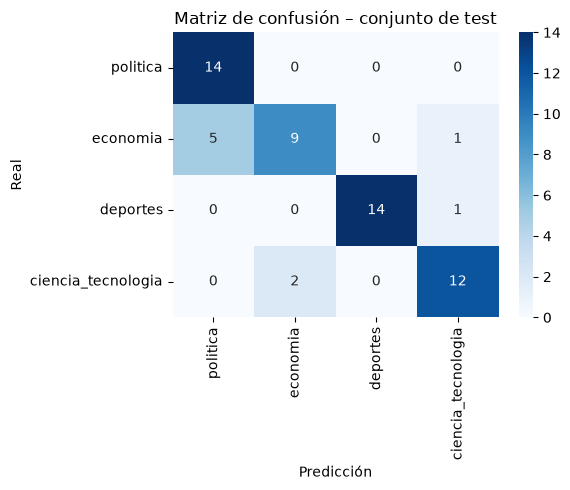

In [11]:
pred = trainer.predict(ds_test)
y_true, y_pred = pred.label_ids, pred.predictions.argmax(-1)
acc_ft = accuracy_score(y_true, y_pred)
f1_ft = f1_score(y_true, y_pred, average="macro")
print(f"Fine-tuned en TEST → Accuracy: {acc_ft:.3f} | F1 macro: {f1_ft:.3f}\n")
print(classification_report(y_true, y_pred, target_names=ETIQUETAS, digits=3))

plt.figure(figsize=(6, 5))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=ETIQUETAS, yticklabels=ETIQUETAS)
plt.xlabel("Predicción"); plt.ylabel("Real"); plt.title("Matriz de confusión – conjunto de test")
plt.tight_layout(); plt.show()

In [12]:
errores = test.assign(prediccion=[id2label[i] for i in y_pred])
errores = errores[errores["etiqueta"] != errores["prediccion"]][["titular", "etiqueta", "prediccion"]]
print(f"{len(errores)} errores en test")
errores

9 errores en test


,titular,etiqueta,prediccion
148,"Luis Felipe Gazitúa, del Consejo Empresarial Chileno- Peruano: “El principal destino de la inversión extranjera chil...",economia,politica
280,Adiós a las tarjetas amarillas y rojas: Uruguay ensaya un nuevo sistema para los árbitros,deportes,ciencia_tecnologia
146,Pensionistas de la ONP recibirán su pensión en casa desde este jueves 15 de octubre,economia,politica
308,"Netflix despedirá a unos 1.000 empleados, el 6 % de su plantilla, según medios",ciencia_tecnologia,economia
149,"Eduardo Grisolle, CEO de 121: “El modelo de las agencias de holding está cumpliendo un ciclo,es el momento de las ag...",economia,politica
185,"La gran transformación del patrimonio: nuevas generaciones, nuevas decisiones",economia,ciencia_tecnologia
180,"Beatriz Boza, socia y líder de Familias Empresarias en EY: “La siguiente gran apuesta de los empresarios peruanos no...",economia,politica
359,Ciberamenazas en América Latina: Perú registró mayor actividad de malware en el primer semestre de 2026,ciencia_tecnologia,economia
144,"Daniel Velandia, economista jefe de Credicorp Capital: “Si las condiciones se dan después de El Niño, al 2028 podrem...",economia,politica


### Reflexión por categoría

- **Mejor desempeño – `deportes` (F1 0.966):** su vocabulario es muy exclusivo (nombres de clubes, "Liga 1", "gol", "empató",
  marcadores como "2-1"), por lo que el modelo casi no lo confunde. El único error fue un titular sobre un nuevo sistema de
  tarjetas para árbitros, que el modelo leyó como tecnología.
- **Peor desempeño – `economia` (F1 0.692, recall 0.60):** 6 de sus 15 noticias de test fueron mal clasificadas, casi todas como
  `politica`. La causa es lingüística: muchas notas económicas de El Comercio son **entrevistas con formato "Nombre, cargo: «cita»"**
  (ej. *"Luis Felipe Gazitúa, del Consejo Empresarial Chileno-Peruano: «…»"*), el mismo formato que domina en política. Además,
  temas como pensiones de la ONP involucran al Estado, lo que acerca el vocabulario al político.
- **`politica` (recall 1.00, precisión 0.74):** el modelo nunca se pierde una noticia política, pero "absorbe" errores de
  economía; tiende a predecir política ante cualquier titular con citas o instituciones públicas.
- **`ciencia_tecnologia` (F1 0.857):** se confunde con economía cuando la noticia trata de empresas tecnológicas
  (ej. despidos en Netflix), un tema que mezcla negocios y tecnología.

## 6. Comparativa: zero-shot vs. LLM débil vs. Transformer fine-tuned (mismo test)

In [13]:
def por_titular(fn, textos):
    t0 = time.perf_counter(); salida = fn(textos)
    return salida, (time.perf_counter() - t0) / len(textos)

textos_test = test["titular"].tolist()

zs_out, lat_zs = por_titular(lambda t: zs(t, candidate_labels=list(NOMBRES), hypothesis_template=PLANTILLA), textos_test)
pred_zs_test = [NOMBRES[r["labels"][0]] for r in zs_out]

pred_llm_test = test["etiqueta_llm"].fillna("sin_etiqueta")
salida_llm, lat_llm = por_titular(lambda t: etiquetar_lote(list(enumerate(t))), textos_test[:20])
if not salida_llm:  # cuota agotada o servicio saturado: no se puede medir
    lat_llm = float("nan")

clf = pipeline("text-classification", model="modelo")
_, lat_ft = por_titular(clf, textos_test)

def fila(nombre, pred, lat, costo, entrena):
    return {"modelo": nombre,
            "accuracy_test": accuracy_score(test["etiqueta"], pred),
            "f1_macro_test": f1_score(test["etiqueta"], pred, average="macro", labels=ETIQUETAS),
            "latencia_s_por_titular": lat, "costo": costo, "requiere_entrenar": entrena}

comparativa = pd.DataFrame([
    fila("Zero-shot (BERT-XNLI)", pred_zs_test, lat_zs, "Gratis, local (~440 MB)", "No"),
    fila(f"LLM débil ({' + '.join(llm['modelo_llm'].unique())})", pred_llm_test, lat_llm, "API externa, por consulta", "No"),
    fila("DistilBERT fine-tuned", [id2label[i] for i in y_pred], lat_ft, "Gratis, local (~540 MB)", "Sí (minutos en CPU)"),
]).round(3)
comparativa

  Error, reintentando en 30 s: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.7-flash\nPlease retry in 23h2m27.172415413s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model

  Error, reintentando en 30 s: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.7-flash\nPlease retry in 23h1m55.621093528s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:  35%|███▍      | 36/104 [00:00<00:00, 295.69it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 615.71it/s]

,modelo,accuracy_test,f1_macro_test,latencia_s_por_titular,costo,requiere_entrenar
0,Zero-shot (BERT-XNLI),0.690,0.685,0.212,"Gratis, local (~440 MB)",No
1,LLM débil (gemini-3.7-flash + gemini-3.5-flash-lite),0.966,0.965,NaN,"API externa, por consulta",No
2,DistilBERT fine-tuned,0.845,0.841,0.025,"Gratis, local (~540 MB)",Sí (minutos en CPU)


### Decisión: ¿qué modelo usar en un entorno real?

| Criterio | Zero-shot | LLM (Gemini) | DistilBERT fine-tuned |
|---|---|---|---|
| F1 macro (test) | 0.685 | **0.965** | 0.841 |
| Latencia | ~0.2 s/titular | ~0.2 s/titular en lotes de 20 (estimada*) + depende de red | **~0.03 s/titular** |
| Costo / dependencia | Gratis, local | API externa, cuota diaria (se agotó durante esta tarea) | Gratis, local |

\* La latencia del LLM no pudo medirse en esta celda porque la cuota gratuita diaria de `gemini-3.7-flash` (20 solicitudes)
se agotó; la estimación proviene de los tiempos observados durante el etiquetado (≈4 s por lote de 20 titulares).

**Elegiría DistilBERT fine-tuned para producción.** Aunque el LLM es más preciso (0.965 vs. 0.841), depende de un servicio
externo con cuotas y saturación (en esta tarea hubo errores 503 y 429), tiene costo por consulta en uso real y una latencia
~8 veces mayor. DistilBERT corre localmente en CPU, responde en milisegundos, no tiene costo marginal y supera ampliamente al
zero-shot (+0.16 de F1 sobre el mismo test). El LLM sigue siendo muy útil **fuera de línea**: para etiquetar o limpiar nuevos
datos de entrenamiento (como se hizo aquí), lo que permitiría reentrenar DistilBERT periódicamente y cerrar la brecha de precisión.

In [14]:
metricas_finales = {
    "n_noticias": int(len(df)),
    "f1_test": float(f1_ft), "accuracy_test": float(acc_ft),
    "f1_zero_shot": float(f1_zs), "accuracy_zero_shot": float(acc_zs),
    "acuerdo_aciertos": int(aciertos), "acuerdo_humano": aciertos / 20,
    "modelo_llm": " + ".join(llm["modelo_llm"].value_counts().index), "fecha": str(date.today()),
    "comparativa": comparativa[["modelo", "accuracy_test", "f1_macro_test", "latencia_s_por_titular"]].to_dict("records"),
}
Path("modelo/metricas.json").write_text(json.dumps(metricas_finales, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"F1 Macro: {f1_ft:.3f} | Zero-shot: {f1_zs:.3f} | Acuerdo LLM-Humano: {aciertos}/20")

F1 Macro: 0.841 | Zero-shot: 0.577 | Acuerdo LLM-Humano: 19/20
